In [141]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
print("Libraries imported successfully!")

Libraries imported successfully!


In [142]:
import os

os.listdir('/content')

['.config', 'car_prices.csv', 'sample_data']

In [143]:
import pandas as pd

df = pd.read_csv('/content/car_prices.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (558837, 16)


,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


In [144]:
print("df exists:", 'df' in globals())
print("df_clean exists:", 'df_clean' in globals())

if 'df_clean' in globals():
    print("Cleaned dataset shape:", df_clean.shape)

df exists: True
df_clean exists: True
Cleaned dataset shape: (19948, 17)


In [145]:
df.head()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


In [146]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

df.info()

Number of Rows: 558837
Number of Columns: 16
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 558837 entries, 0 to 558836
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   year          558837 non-null  int64  
 1   make          548536 non-null  object 
 2   model         548438 non-null  object 
 3   trim          548186 non-null  object 
 4   body          545642 non-null  object 
 5   transmission  493485 non-null  object 
 6   vin           558833 non-null  object 
 7   state         558837 non-null  object 
 8   condition     547017 non-null  float64
 9   odometer      558743 non-null  float64
 10  color         558088 non-null  object 
 11  interior      558088 non-null  object 
 12  seller        558837 non-null  object 
 13  mmr           558799 non-null  float64
 14  sellingprice  558825 non-null  float64
 15  saledate      558825 non-null  object 
dtypes: float64(4), int64(1), object(11)
memory usag

In [147]:
df.isnull().sum()

,0
year,0
make,10301
model,10399
trim,10651
body,13195
transmission,65352
vin,4
state,0
condition,11820
odometer,94


In [148]:
# Missing value percentage

missing_analysis = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_analysis.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Values,Missing Percentage
transmission,65352,11.69
body,13195,2.36
condition,11820,2.12
trim,10651,1.91
model,10399,1.86
make,10301,1.84
color,749,0.13
interior,749,0.13
odometer,94,0.02
mmr,38,0.01


In [149]:
# Check records with missing selling price

df[df['sellingprice'].isnull()]

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
306447,2013,Hyundai,Sonata,GLS,Sedan,automatic,5npeb4ac6dh687932,il,19.0,37254.0,gray,gray,kfl llc,NaN,NaN,NaN
406524,2013,Chrysler,300,Base,Sedan,automatic,2c3ccaag9dh723146,il,27.0,44208.0,silver,black,kfl llc,NaN,NaN,NaN
422358,2013,Hyundai,Sonata,GLS,Sedan,NaN,5npeb4ac3dh735368,az,28.0,44299.0,blue,gray,kfl llc,NaN,NaN,NaN
429644,2013,Chrysler,200,Touring,Sedan,automatic,1c3ccbbb9dn718531,il,25.0,47344.0,white,black,kfl llc,NaN,NaN,NaN
429660,2013,Dodge,Avenger,SXT,Sedan,automatic,1c3cdzcg5dn741076,il,34.0,44525.0,gray,black,kfl llc,NaN,NaN,NaN
429786,2013,Hyundai,Accent,GLS,Sedan,automatic,kmhct4ae7du450468,il,3.0,43135.0,silver,gray,kfl llc,NaN,NaN,NaN
431905,2013,Kia,Soul,Base,Wagon,automatic,kndjt2a5xd7765280,va,19.0,29465.0,silver,black,kfl llc,NaN,NaN,NaN
457035,2014,Hyundai,Elantra,SE,Sedan,automatic,5npdh4ae3eh504144,il,19.0,20775.0,white,—,kfl llc,NaN,NaN,NaN
457803,2013,Dodge,Charger,SE,Sedan,automatic,2c3cdxbg6dh688757,il,19.0,45355.0,white,black,kfl llc,NaN,NaN,NaN
522495,2012,Ford,Fusion,SEL,sedan,automatic,3fahp0jg5cr241590,va,26.0,51648.0,black,gray,kfl llc,NaN,NaN,NaN


In [150]:
# Check records with missing MMR

df[df['mmr'].isnull()]

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
306447,2013,Hyundai,Sonata,GLS,Sedan,automatic,5npeb4ac6dh687932,il,19.0,37254.0,gray,gray,kfl llc,NaN,NaN,NaN
406524,2013,Chrysler,300,Base,Sedan,automatic,2c3ccaag9dh723146,il,27.0,44208.0,silver,black,kfl llc,NaN,NaN,NaN
408161,2015,Volkswagen,Jetta,SE PZEV w/Connectivity,Navitgation,Sedan,automatic,3vwd17aj4fm201708,NaN,46.0,4802,silver,gray,NaN,13200.0,16500
417835,2015,Volkswagen,Jetta,SE PZEV w/Connectivity,Navitgation,Sedan,automatic,3vwd17aj2fm258506,NaN,1.0,9410,white,gray,NaN,13300.0,10500
421289,2015,Volkswagen,Jetta,SE PZEV w/Connectivity,Navitgation,Sedan,automatic,3vwd17aj3fm276741,NaN,46.0,1167,blue,black,NaN,13200.0,12700
422358,2013,Hyundai,Sonata,GLS,Sedan,NaN,5npeb4ac3dh735368,az,28.0,44299.0,blue,gray,kfl llc,NaN,NaN,NaN
424161,2015,Volkswagen,Jetta,SE PZEV w/Connectivity,Navitgation,Sedan,automatic,3vwd17aj2fm285365,NaN,1.0,2172,gray,black,NaN,14050.0,8250
427040,2015,Volkswagen,Jetta,SE PZEV w/Connectivity,Navitgation,Sedan,automatic,3vwd17aj0fm227318,NaN,41.0,14872,gray,black,NaN,13700.0,14300
427043,2015,Volkswagen,Jetta,SE PZEV w/Connectivity,Navitgation,Sedan,automatic,3vwd17aj6fm218641,NaN,49.0,12655,red,black,NaN,13850.0,14500
429644,2013,Chrysler,200,Touring,Sedan,automatic,1c3ccbbb9dn718531,il,25.0,47344.0,white,black,kfl llc,NaN,NaN,NaN


In [151]:
df['transmission'].value_counts(dropna=False)

,count
transmission,
automatic,475915
NaN,65352
manual,17544
sedan,15
Sedan,11


In [152]:
# Check vehicle condition distribution

df['condition'].value_counts(dropna=False).sort_index()

,count
condition,
1.0,7364
2.0,20790
3.0,10803
4.0,19922
5.0,11222
11.0,87
12.0,95
13.0,82
14.0,134


In [153]:
# Check unique body types

df['body'].value_counts(dropna=False)

,count
body,
Sedan,199437
SUV,119292
sedan,41906
suv,24552
Hatchback,21380
Minivan,21363
Coupe,14602
Wagon,13630
Crew Cab,13280


In [154]:
# Check unique car brands

df['make'].nunique()
#df['make'].value_counts().head(10)

96

In [155]:
df_clean = df.copy()

print("Working copy created successfully!")

Working copy created successfully!


In [156]:
# Remove records with missing selling price

df_clean = df_clean.dropna(subset=['sellingprice'])

print("Remaining records:", len(df_clean))

Remaining records: 558825


In [157]:
df_clean['sellingprice'].isnull().sum()

np.int64(0)

In [158]:
print("Original dataset:", len(df))
print("Cleaned dataset:", len(df_clean))
print("Missing selling prices:", df['sellingprice'].isnull().sum())

Original dataset: 558837
Cleaned dataset: 558825
Missing selling prices: 12


In [159]:
# Reset index after removing missing selling prices

df_clean = df_clean.reset_index(drop=True)

print("Index reset successfully!")
print("Total records:", len(df_clean))

Index reset successfully!
Total records: 558825


In [160]:
df_clean.head()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


In [161]:
df_clean.head()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


In [162]:
df_clean[['sellingprice', 'mmr']].head()

,sellingprice,mmr
0,21500.0,20500.0
1,21500.0,20800.0
2,30000.0,31900.0
3,27750.0,27500.0
4,67000.0,66000.0


In [163]:
# Check missing categorical values

categorical_columns = [
    'make', 'model', 'trim', 'body',
    'transmission', 'color', 'interior'
]

df_clean[categorical_columns].isnull().sum()

,0
make,10301
model,10399
trim,10651
body,13195
transmission,65351
color,749
interior,749


In [164]:
# Fill missing categorical values with Unknown

categorical_columns = [
    'make', 'model', 'trim', 'body',
    'transmission', 'color', 'interior'
]

df_clean[categorical_columns] = (
    df_clean[categorical_columns].fillna('Unknown')
)

print("Missing categorical values handled!")

Missing categorical values handled!


In [165]:
df_clean[categorical_columns].isnull().sum()

,0
make,0
model,0
trim,0
body,0
transmission,0
color,0
interior,0


In [166]:
# Check missing values in all columns

df_clean.isnull().sum()

,0
year,0
make,0
model,0
trim,0
body,0
transmission,0
vin,4
state,0
condition,11820
odometer,94


In [167]:
# Check vehicle condition values

df_clean['condition'].describe()

,condition
count,547005.000000
mean,30.672557
std,13.402872
min,1.000000
25%,23.000000
50%,35.000000
75%,42.000000
max,49.000000


In [168]:
# Check condition rating frequency

df_clean['condition'].value_counts().sort_index()


,count
condition,
1.0,7364
2.0,20790
3.0,10802
4.0,19922
5.0,11222
11.0,87
12.0,95
13.0,82
14.0,134


In [169]:
# Check odometer statistics

df_clean['odometer'].describe()

,odometer
count,558731.000000
mean,68320.652287
std,53398.923572
min,1.000000
25%,28370.500000
50%,52255.000000
75%,99110.500000
max,999999.000000


In [170]:
# Check missing odometer records

df_clean[df_clean['odometer'].isnull()][
    ['year', 'make', 'model', 'odometer', 'sellingprice']
].head(10)

,year,make,model,odometer,sellingprice
2690,2010,Unknown,Unknown,NaN,2200.0
3360,2007,Ford,Edge,NaN,15500.0
4158,2005,Chevrolet,Equinox,NaN,27500.0
4301,2005,Nissan,Murano,NaN,400.0
4685,2003,BMW,7 Series,NaN,3700.0
5119,2000,Mercedes-Benz,M-Class,NaN,1500.0
5219,1998,dodge,caravan,NaN,300.0
5222,1995,Honda,Accord,NaN,400.0
7566,2002,Ford,F-350 Super Duty,NaN,1.0
7683,1999,ford,f150,NaN,2400.0


In [171]:
# Check vehicles with extremely high mileage

df_clean[df_clean['odometer'] > 300000][
    ['year', 'make', 'model', 'odometer', 'sellingprice']
].head(20)

,year,make,model,odometer,sellingprice
275,2013,Hyundai,Elantra Coupe,999999.0,2500.0
2822,2009,Ford,Ranger,312235.0,2000.0
3760,2006,Chevrolet,Express Cargo,315411.0,2300.0
4155,2005,Dodge,Sprinter Cargo,316490.0,6500.0
4250,2005,Honda,CR-V,348070.0,3400.0
4339,2005,Lincoln,Town Car,381875.0,1100.0
4626,2003,Chevrolet,Silverado 1500,999999.0,700.0
4941,2001,Ford,F-250 Super Duty,311164.0,700.0
4953,2001,Chevrolet,Silverado 1500HD,355898.0,2600.0
4974,2002,Subaru,Outback,324030.0,1000.0


In [172]:
# Calculate median odometer

odometer_median = df_clean['odometer'].median()

print("Median odometer:", odometer_median)

Median odometer: 52255.0


In [173]:
# Fill missing odometer values with median

df_clean['odometer'] = df_clean['odometer'].fillna(
    odometer_median
)

print("Missing odometer values handled!")

Missing odometer values handled!


In [174]:
df_clean['odometer'].isnull().sum()

np.int64(0)

In [175]:
# Count vehicles with 999999 odometer

(df_clean['odometer'] == 999999).sum()

np.int64(72)

In [176]:
# Check vehicles above 300000 miles

df_clean[df_clean['odometer'] > 300000].shape[0]

744

In [177]:
# Replace suspicious placeholder mileage with missing values

df_clean['odometer'] = df_clean['odometer'].replace(
    999999, np.nan
)

In [178]:
# Check missing odometer values after replacement

df_clean['odometer'].isnull().sum()

np.int64(72)

In [179]:
# Check missing condition values

df_clean['condition'].isnull().sum()

np.int64(11820)

In [180]:
# Check condition value distribution

df_clean['condition'].value_counts().sort_index()

,count
condition,
1.0,7364
2.0,20790
3.0,10802
4.0,19922
5.0,11222
11.0,87
12.0,95
13.0,82
14.0,134


In [181]:
# Check condition range

print("Minimum condition:", df_clean['condition'].min())
print("Maximum condition:", df_clean['condition'].max())

Minimum condition: 1.0
Maximum condition: 49.0


In [182]:
condition_median = df_clean['condition'].median()

print("Median condition:", condition_median)

Median condition: 35.0


In [183]:
# Fill missing condition values with median

df_clean['condition'] = df_clean['condition'].fillna(
    condition_median
)

print("Missing condition values handled!")

Missing condition values handled!


In [184]:
df_clean['condition'].isnull().sum()

np.int64(0)

In [185]:
# Check missing values in all columns

missing_values = df_clean.isnull().sum()

missing_values[missing_values > 0]

,0
vin,4
odometer,72
mmr,26


In [186]:
# Check duplicate records

print("Duplicate records:", df_clean.duplicated().sum())


Duplicate records: 0


In [187]:
# Check unique values in categorical columns

for col in ['make', 'transmission', 'body', 'color', 'interior']:
    print(f"\n{col.upper()} - Unique values:")
    print(df_clean[col].nunique())


MAKE - Unique values:
97

TRANSMISSION - Unique values:
5

BODY - Unique values:
88

COLOR - Unique values:
47

INTERIOR - Unique values:
18


In [188]:
# Check transmission category values

df_clean['transmission'].value_counts()

,count
transmission,
automatic,475904
Unknown,65351
manual,17544
sedan,15
Sedan,11


In [189]:
# Check body category values

df_clean['body'].value_counts()

,count
body,
Sedan,199429
SUV,119292
sedan,41903
suv,24552
Hatchback,21380
Minivan,21363
Coupe,14602
Wagon,13629
Crew Cab,13280


In [190]:
# Standardize body category capitalization

df_clean['body'] = df_clean['body'].apply(
    lambda x: x.title() if x != 'Unknown' else x
)

print("Body categories standardized!")

Body categories standardized!


In [191]:
# Check standardized body categories

df_clean['body'].value_counts()

,count
body,
Sedan,241332
Suv,143844
Hatchback,26237
Minivan,25529
Coupe,17752
Crew Cab,16394
Wagon,16128
Unknown,13195
Convertible,10476


In [192]:
# Correct SUV abbreviation

df_clean['body'] = df_clean['body'].replace({
    'Suv': 'SUV'
})

print("SUV capitalization corrected!")

SUV capitalization corrected!


In [193]:
# Check car color categories

df_clean['color'].value_counts()

,count
color,
black,110969
white,106670
silver,83385
gray,82854
blue,51138
red,43569
—,24685
green,11382
gold,11342


In [194]:
# Replace placeholder values with Unknown

df_clean['color'] = df_clean['color'].replace({
    '—': 'Unknown'
})

print("Color placeholder values handled!")

Color placeholder values handled!


In [195]:
# Standardize color capitalization

df_clean['color'] = df_clean['color'].apply(
    lambda x: x.title() if x != 'Unknown' else x
)

print("Color categories standardized!")

Color categories standardized!


In [196]:
# Check cleaned color categories

df_clean['color'].value_counts()

,count
color,
Black,110969
White,106670
Silver,83385
Gray,82854
Blue,51138
Red,43569
Unknown,25434
Green,11382
Gold,11342


In [197]:
# Check interior category distribution

df_clean['interior'].value_counts()

,count
interior,
black,244324
gray,178575
beige,59758
tan,44093
—,17076
brown,8640
red,1363
blue,1143
silver,1104


In [198]:
# Standardize interior category capitalization
df_clean['interior'] = df_clean['interior'].apply(
    lambda x: x.title() if x != 'Unknown' else x
)

# Replace placeholder values
df_clean['interior'] = df_clean['interior'].replace(
    '—', 'Unknown'
)

print("Interior categories standardized!")

Interior categories standardized!


In [199]:
# Check manufacturer name distribution

df_clean['make'].value_counts()

,count
make,
Ford,93553
Chevrolet,60197
Nissan,53946
Toyota,39871
Dodge,30708
Honda,27206
Hyundai,21811
BMW,20719
Kia,18075


In [200]:
# Standardize manufacturer name capitalization

df_clean['make'] = df_clean['make'].apply(
    lambda x: x.title() if x != 'Unknown' else x
)

print("Manufacturer names capitalization standardized!")

Manufacturer names capitalization standardized!


In [201]:
df_clean['make'].value_counts()

,count
make,
Ford,93996
Chevrolet,60587
Nissan,54017
Toyota,39966
Dodge,30953
Honda,27351
Hyundai,21831
Bmw,20793
Kia,18082


In [202]:
# Standardize manufacturer aliases

make_mapping = {
    'Bmw': 'BMW',
    'Gmc': 'GMC',
    'Mini': 'MINI',
    'Fiat': 'FIAT',
    'Vw': 'Volkswagen',
    'Landrover': 'Land Rover',
    'Mercedes': 'Mercedes-Benz',
    'Mercedes-B': 'Mercedes-Benz'
}

df_clean['make'] = df_clean['make'].replace(make_mapping)

print("Manufacturer aliases standardized!")

Manufacturer aliases standardized!


In [203]:
df_clean['make'].value_counts()

,count
make,
Ford,93996
Chevrolet,60587
Nissan,54017
Toyota,39966
Dodge,30953
Honda,27351
Hyundai,21831
BMW,20793
Kia,18082


In [204]:
df_clean['model'].value_counts().head(30)

,count
model,
Altima,19349
F-150,14479
Fusion,12945
Camry,12545
Escape,11861
Unknown,10399
Focus,10394
Accord,9127
3 Series,8204


In [205]:
df_clean['model'].value_counts().tail(30)

,count
model,
golf,1
rrs,1
aveo,1
cherokee,1
tahoe,1
avenger,1
c240s,1
carrera,1
equinox,1


In [206]:
df_clean['model'] = df_clean['model'].apply(
    lambda x: x.title() if x != 'Unknown' else x
)

In [207]:
df_clean['model'].value_counts().tail(30)

,count
model,
C240S,1
Allure,1
350,1
1,1
323I,1
Swift,1
Interstate,1
Le Baron,1
Spirit,1


In [208]:
model_mapping = {
    'Cts-V Wagon': 'CTS-V Wagon',
    'Wrx': 'WRX',
    '328I': '328i',
    '323I': '323i',
    'Lx 450': 'LX 450'
}

df_clean['model'] = df_clean['model'].replace(model_mapping)

In [209]:
df_clean['trim'].value_counts().head(30)

,count
trim,
Base,55815
SE,43646
LX,20756
Limited,18367
LT,16915
XLT,16741
LS,13427
LE,12903
GLS,12327


In [210]:
df_clean['trim'].value_counts().tail(30)

,count
trim,
420SEL,1
2.5T SE,1
60,1
300SE,1
3.2 Premier Plus,1
E400 Sport Hybrid,1
GS Plus,1
Lux SULEV,1
awd 2.0t,1


In [211]:
df_clean[df_clean['trim'].str.contains('anniversar', case=False, na=False)][
    ['make', 'model', 'trim']
]

,make,model,trim
15606,Ford,F-150,60th Anniversary
15673,Ford,F-150,60th Anniversary
28330,Nissan,Maxima,SE 20th Anniversary
28402,Nissan,Maxima,SE 20th Anniversary
30082,Honda,Accord,25th Anniversary
43316,Jeep,Wrangler,Unlimited 70th Anniversary
48150,Subaru,Legacy,L 35th Anniversary Edition
49471,Honda,Accord,10th Anniversary
55112,Ford,F-150,60th Anniversary
67383,Nissan,350Z,anniversar


In [212]:
df_clean['trim'] = df_clean['trim'].replace('anniversar', 'Unknown')

In [213]:
df_clean['body'].value_counts().head(30)

,count
body,
Sedan,241332
SUV,143844
Hatchback,26237
Minivan,25529
Coupe,17752
Crew Cab,16394
Wagon,16128
Unknown,13195
Convertible,10476


In [214]:
body_mapping = {
    'Supercrew': 'SuperCrew',
    'Supercab': 'SuperCab',
    'Crewmax Cab': 'CrewMax Cab',
    'Cts Coupe': 'CTS Coupe'
}

df_clean['body'] = df_clean['body'].replace(body_mapping)

In [215]:
df_clean['transmission'].value_counts(dropna=False)

,count
transmission,
automatic,475904
Unknown,65351
manual,17544
sedan,15
Sedan,11


In [216]:
df_clean['transmission'] = df_clean['transmission'].str.title()

In [217]:
df_clean['transmission'].value_counts()

,count
transmission,
Automatic,475904
Unknown,65351
Manual,17544
Sedan,26


In [218]:
df_clean['state'].value_counts(dropna=False)

,count
state,
fl,82945
ca,73148
pa,53907
tx,45913
ga,34750
nj,27784
il,23478
nc,21845
oh,21575


In [219]:
state_mapping = {
    'CA': 'California',
    'FL': 'Florida',
    'PA': 'Pennsylvania',
    'TX': 'Texas',
    'GA': 'Georgia',
    'NJ': 'New Jersey',
    'NC': 'North Carolina',
    'IL': 'Illinois',
    'TN': 'Tennessee',
    'OH': 'Ohio',
    'MO': 'Missouri',
    'MI': 'Michigan',
    'VA': 'Virginia',
    'MD': 'Maryland',
    'NV': 'Nevada',
    'WI': 'Wisconsin',
    'MN': 'Minnesota',
    'AZ': 'Arizona',
    'WA': 'Washington',
    'MA': 'Massachusetts',
    'NY': 'New York',
    'CO': 'Colorado',
    'IN': 'Indiana',
    'NE': 'Nebraska',
    'SC': 'South Carolina',
    'LA': 'Louisiana',
    'UT': 'Utah',
    'OR': 'Oregon',
    'HI': 'Hawaii',
    'OK': 'Oklahoma',
    'AL': 'Alabama',
    'MS': 'Mississippi',
    'NM': 'New Mexico',
    'ON': 'Ontario',
    'QC': 'Quebec',
    'AB': 'Alberta',
    'PR': 'Puerto Rico'
}

df_clean['state'] = df_clean['state'].str.upper().replace(state_mapping)

In [220]:
df_clean['state'].value_counts()

,count
state,
Florida,82945
California,73148
Pennsylvania,53907
Texas,45913
Georgia,34750
New Jersey,27784
Illinois,23478
North Carolina,21845
Ohio,21575


In [221]:
df_clean['seller'].value_counts().head(30)

,count
seller,
nissan-infiniti lt,19693
ford motor credit company llc,19162
the hertz corporation,18299
santander consumer,15285
avis corporation,12540
nissan infiniti lt,9962
wells fargo dealer services,8796
tdaf remarketing,7209
enterprise veh exchange/rental,6853


In [222]:
df_clean['seller'] = df_clean['seller'].str.title()

In [223]:
df_clean['seller'].value_counts().head(30)

,count
seller,
Nissan-Infiniti Lt,19693
Ford Motor Credit Company Llc,19162
The Hertz Corporation,18299
Santander Consumer,15285
Avis Corporation,12540
Nissan Infiniti Lt,9962
Wells Fargo Dealer Services,8796
Tdaf Remarketing,7209
Enterprise Veh Exchange/Rental,6853


In [224]:
seller_mapping = {
    'Ford Motor Credit Company Llc': 'Ford Motor Credit Company LLC',
    'Ford Motor Credit Company Llc Pd': 'Ford Motor Credit Company LLC PD',
    'Ge Fleet Services For Itself/Servicer': 'GE Fleet Services For Itself/Servicer',
    'Jpmorgan Chase Bank N.A.': 'JPMorgan Chase Bank N.A.',
    'Gm Financial': 'GM Financial',
    'Gm Remarketing': 'GM Remarketing',
    'Lease Plan Usa': 'Lease Plan USA'
}

df_clean['seller'] = df_clean['seller'].replace(seller_mapping)

In [225]:
df_clean['color'].value_counts()

,count
color,
Black,110969
White,106670
Silver,83385
Gray,82854
Blue,51138
Red,43569
Unknown,25434
Green,11382
Gold,11342


In [226]:
df_clean['interior'].value_counts()

,count
interior,
Black,244324
Gray,178575
Beige,59758
Tan,44093
Unknown,17825
Brown,8640
Red,1363
Blue,1143
Silver,1104


In [227]:
df_clean['vin'].isnull().sum()

np.int64(4)

In [228]:
df_clean['vin'].nunique()

550285

In [229]:
df_clean['vin'].str.len().value_counts().sort_index()

,count
vin,
9.0,22
17.0,558799


In [230]:
df_clean['year'].describe()


,year
count,558825.000000
mean,2010.038864
std,3.966882
min,1982.000000
25%,2007.000000
50%,2012.000000
75%,2013.000000
max,2015.000000


In [231]:
df_clean['year'].isnull().sum()

np.int64(0)

In [232]:
df_clean['condition'].describe()

,condition
count,558825.000000
mean,30.764089
std,13.274980
min,1.000000
25%,24.000000
50%,35.000000
75%,41.000000
max,49.000000


In [233]:
df_clean['condition'].isnull().sum()

np.int64(0)

In [234]:
df_clean['odometer'].describe()

,odometer
count,558753.000000
mean,68197.894982
std,52340.316132
min,1.000000
25%,28371.000000
50%,52255.000000
75%,99086.000000
max,980113.000000


In [235]:
df_clean[df_clean['odometer'] > 300000][
    ['year', 'make', 'model', 'odometer']
].sort_values(by='odometer', ascending=False).head(20)

,year,make,model,odometer
416792,1993,Ford,Explorer,980113.0
321778,1996,Toyota,Corolla,959276.0
281284,2002,Saturn,Vue,694978.0
94514,2003,Saturn,Vue,694978.0
230552,2007,Toyota,Highlander,621388.0
396639,2008,GMC,Yukon Xl,580956.0
303956,2007,Toyota,Prius,537334.0
273643,2013,Mitsubishi,Lancer,522212.0
20043,2006,Dodge,Ram Pickup 2500,500227.0
511122,2003,Acura,Tl,495757.0


In [236]:
(df_clean['odometer'] > 300000).sum()

np.int64(672)

In [237]:
(df_clean['odometer'] > 500000).sum()

np.int64(9)

In [238]:
df_clean[df_clean['odometer'] > 500000][
    ['year', 'make', 'model', 'odometer']
]

,year,make,model,odometer
20043,2006,Dodge,Ram Pickup 2500,500227.0
94514,2003,Saturn,Vue,694978.0
230552,2007,Toyota,Highlander,621388.0
273643,2013,Mitsubishi,Lancer,522212.0
281284,2002,Saturn,Vue,694978.0
303956,2007,Toyota,Prius,537334.0
321778,1996,Toyota,Corolla,959276.0
396639,2008,GMC,Yukon Xl,580956.0
416792,1993,Ford,Explorer,980113.0


In [239]:
df_clean[df_clean['odometer'] < 100][
    ['year', 'make', 'model', 'odometer']
].head(20)

,year,make,model,odometer
61,2015,Audi,A3,31.0
123,2013,Infiniti,G Sedan,68.0
316,2013,Hyundai,Sonata Hybrid,20.0
338,2013,Hyundai,Santa Fe,66.0
444,2013,Lexus,Ls 460,71.0
697,2013,Nissan,Maxima,1.0
1000,2012,Chrysler,200,1.0
1723,2012,Mercedes-Benz,M-Class,1.0
2082,2011,Unknown,Unknown,1.0
2942,2009,Honda,Civic,1.0


In [240]:
(df_clean['odometer'] == 1).sum()

np.int64(1318)

In [241]:
df_clean[df_clean['odometer'] <= 100]['odometer'].value_counts().sort_index()

,count
odometer,
1.0,1318
2.0,18
3.0,9
4.0,9
5.0,17
6.0,13
7.0,13
8.0,18
9.0,11


In [242]:
df_clean[df_clean['odometer'] == 1]['year'].value_counts().sort_index()

,count
year,
1990,3
1992,4
1993,3
1994,8
1995,15
1996,25
1997,24
1998,44
1999,75


In [243]:
df_clean[df_clean['odometer'] == 1][
    ['year', 'make', 'model', 'sellingprice', 'mmr']
].head(20)

,year,make,model,sellingprice,mmr
697,2013,Nissan,Maxima,1000.0,16950.0
1000,2012,Chrysler,200,1300.0,10450.0
1723,2012,Mercedes-Benz,M-Class,18500.0,69000.0
2082,2011,Unknown,Unknown,11500.0,18300.0
2942,2009,Honda,Civic,1000.0,9325.0
3076,2008,Honda,Civic,1300.0,7900.0
3090,2008,Chrysler,300,1300.0,32500.0
3166,2008,Jeep,Compass,1800.0,5850.0
3300,2007,Dodge,Charger,1200.0,12450.0
3555,2006,Audi,A4,3100.0,8800.0


In [244]:
df_clean['odometer'] = df_clean['odometer'].replace(1, np.nan)


In [245]:
df_clean['odometer'].isnull().sum()

np.int64(1390)

In [246]:
odometer_median = df_clean['odometer'].median()

print(odometer_median)

52387.0


In [247]:
df_clean['odometer'] = df_clean['odometer'].fillna(odometer_median)

In [248]:
df_clean['odometer'].isnull().sum()

np.int64(0)

In [249]:
df_clean['odometer'].describe()

,odometer
count,558825.000000
mean,68319.411313
std,52237.856979
min,2.000000
25%,28578.000000
50%,52387.000000
75%,99081.000000
max,980113.000000


In [250]:
df_clean['sellingprice'].describe()

,sellingprice
count,558825.000000
mean,13611.358810
std,9749.501628
min,1.000000
25%,6900.000000
50%,12100.000000
75%,18200.000000
max,230000.000000


In [251]:
df[['sellingprice', 'mmr']].describe()

,sellingprice,mmr
count,558825.000000,558799.000000
mean,13611.358810,13769.377495
std,9749.501628,9679.967174
min,1.000000,25.000000
25%,6900.000000,7100.000000
50%,12100.000000,12250.000000
75%,18200.000000,18300.000000
max,230000.000000,182000.000000


In [252]:
df['saledate'].head(10)

,saledate
0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)
5,Tue Dec 30 2014 12:00:00 GMT-0800 (PST)
6,Wed Dec 17 2014 12:30:00 GMT-0800 (PST)
7,Tue Dec 16 2014 13:00:00 GMT-0800 (PST)
8,Thu Dec 18 2014 12:00:00 GMT-0800 (PST)
9,Tue Jan 20 2015 04:00:00 GMT-0800 (PST)


In [253]:
df_clean['saledate'] = pd.to_datetime(
    df_clean['saledate'],
    format='mixed',
    errors='coerce',
    utc=True
)

In [254]:
df_clean['saledate'].head(10)

,saledate
0,2014-12-16 04:30:00+00:00
1,2014-12-16 04:30:00+00:00
2,2015-01-14 20:30:00+00:00
3,2015-01-28 20:30:00+00:00
4,2014-12-18 04:30:00+00:00
5,2014-12-30 04:00:00+00:00
6,2014-12-17 04:30:00+00:00
7,2014-12-16 05:00:00+00:00
8,2014-12-18 04:00:00+00:00
9,2015-01-19 20:00:00+00:00


In [255]:
df_clean['sale_date'] = (
    df_clean['saledate']
    .dt.tz_convert('America/Los_Angeles')
    .dt.date
)

In [256]:
df_clean[['saledate', 'sale_date']].head(10)

,saledate,sale_date
0,2014-12-16 04:30:00+00:00,2014-12-15
1,2014-12-16 04:30:00+00:00,2014-12-15
2,2015-01-14 20:30:00+00:00,2015-01-14
3,2015-01-28 20:30:00+00:00,2015-01-28
4,2014-12-18 04:30:00+00:00,2014-12-17
5,2014-12-30 04:00:00+00:00,2014-12-29
6,2014-12-17 04:30:00+00:00,2014-12-16
7,2014-12-16 05:00:00+00:00,2014-12-15
8,2014-12-18 04:00:00+00:00,2014-12-17
9,2015-01-19 20:00:00+00:00,2015-01-19


In [257]:
print(df_clean['sale_date'].dtype)

print(df_clean['sale_date'].head(10))

print(df_clean['sale_date'].apply(type).value_counts())

object
0    2014-12-15
1    2014-12-15
2    2015-01-14
3    2015-01-28
4    2014-12-17
5    2014-12-29
6    2014-12-16
7    2014-12-15
8    2014-12-17
9    2015-01-19
Name: sale_date, dtype: object
sale_date
<class 'datetime.date'>                          558799
<class 'pandas._libs.tslibs.nattype.NaTType'>        26
Name: count, dtype: int64


In [258]:
print("Dataset shape:", df_clean.shape)
print("Total rows:", len(df_clean))
print("Duplicate rows:", df_clean.duplicated().sum())

Dataset shape: (558825, 17)
Total rows: 558825
Duplicate rows: 0


In [259]:
print("Original dataset shape:", df.shape)
print("Current cleaned dataset shape:", df_clean.shape)

print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nDuplicate index count:")
print(df_clean.index.duplicated().sum())

print("\nMissing sale dates:")
print(df_clean['sale_date'].isna().sum())

Original dataset shape: (558837, 16)
Current cleaned dataset shape: (558825, 17)

Column names:
['year', 'make', 'model', 'trim', 'body', 'transmission', 'vin', 'state', 'condition', 'odometer', 'color', 'interior', 'seller', 'mmr', 'sellingprice', 'saledate', 'sale_date']

Duplicate index count:
0

Missing sale dates:
26


In [260]:
df_clean['sale_date'] = pd.to_datetime(
    df_clean['sale_date'],
    errors='coerce'
)

print("Earliest sale date:", df_clean['sale_date'].min())
print("Latest sale date:", df_clean['sale_date'].max())
print("Missing sale dates:", df_clean['sale_date'].isna().sum())

Earliest sale date: 2013-12-31 00:00:00
Latest sale date: 2015-07-20 00:00:00
Missing sale dates: 26


In [261]:
print("Earliest sale date:", df_clean['sale_date'].min())
print("Latest sale date:", df_clean['sale_date'].max())
print("Missing sale dates:", df_clean['sale_date'].isnull().sum())

Earliest sale date: 2013-12-31 00:00:00
Latest sale date: 2015-07-20 00:00:00
Missing sale dates: 26


In [262]:
exchange_url = (
    'https://fred.stlouisfed.org/graph/fredgraph.csv'
    '?id=DEXINUS&cosd=2013-12-31&coed=2015-07-20'
)

exchange_rates = pd.read_csv(exchange_url)

exchange_rates.head()

,observation_date,DEXINUS
0,2013-12-31,61.92
1,2014-01-01,NaN
2,2014-01-02,62.31
3,2014-01-03,62.17
4,2014-01-06,62.31


In [263]:
exchange_rates['observation_date'] = pd.to_datetime(
    exchange_rates['observation_date']
)

exchange_rates['DEXINUS'] = pd.to_numeric(
    exchange_rates['DEXINUS'],
    errors='coerce'
)

exchange_rates = exchange_rates.sort_values(
    'observation_date'
)

exchange_rates['DEXINUS'] = exchange_rates['DEXINUS'].ffill()

exchange_rates.head(10)

,observation_date,DEXINUS
0,2013-12-31,61.92
1,2014-01-01,61.92
2,2014-01-02,62.31
3,2014-01-03,62.17
4,2014-01-06,62.31
5,2014-01-07,62.30
6,2014-01-08,62.07
7,2014-01-09,62.07
8,2014-01-10,61.45
9,2014-01-13,61.52


In [264]:
print("Original selling price:")
print(df['sellingprice'].describe())

print("\nCurrent selling price:")
print(df_clean['sellingprice'].describe())

print("\nExchange rate:")
print(exchange_rates['DEXINUS'].describe())

Original selling price:
count    558825.000000
mean      13611.358810
std        9749.501628
min           1.000000
25%        6900.000000
50%       12100.000000
75%       18200.000000
max      230000.000000
Name: sellingprice, dtype: float64

Current selling price:
count    558825.000000
mean      13611.358810
std        9749.501628
min           1.000000
25%        6900.000000
50%       12100.000000
75%       18200.000000
max      230000.000000
Name: sellingprice, dtype: float64

Exchange rate:
count    405.000000
mean      61.669390
std        1.337627
min       58.300000
25%       60.670000
50%       61.760000
75%       62.520000
max       64.210000
Name: DEXINUS, dtype: float64


In [265]:
print("Original selling price:", df['sellingprice'].median())
print("Original MMR:", df['mmr'].median())
print("Current exchange rate median:", exchange_rates['DEXINUS'].median())

Original selling price: 12100.0
Original MMR: 12250.0
Current exchange rate median: 61.76


In [266]:
# Create dataset containing records with valid sale dates
df_valid_dates = df_clean[df_clean['sale_date'].notna()].copy()

# Match each sale date with its historical USD-to-INR exchange rate
df_valid_dates = pd.merge_asof(
    df_valid_dates.sort_values('sale_date'),
    exchange_rates[['observation_date', 'DEXINUS']].sort_values('observation_date'),
    left_on='sale_date',
    right_on='observation_date',
    direction='backward'
)

# Convert USD prices into INR
df_valid_dates['sellingprice_inr'] = (
    df_valid_dates['sellingprice'] * df_valid_dates['DEXINUS']
)

df_valid_dates['mmr_inr'] = (
    df_valid_dates['mmr'] * df_valid_dates['DEXINUS']
)

print("Valid-date dataset:", df_valid_dates.shape)
print(df_valid_dates[['sellingprice_inr', 'mmr_inr']].describe())

Valid-date dataset: (558799, 21)
       sellingprice_inr       mmr_inr
count      5.587990e+05  5.587990e+05
mean       8.533552e+05  8.633003e+05
std        6.123078e+05  6.080798e+05
min        6.173000e+01  1.536500e+03
25%        4.309050e+05  4.451370e+05
50%        7.606160e+05  7.678260e+05
75%        1.140895e+06  1.146483e+06
max        1.427610e+07  1.168622e+07


In [267]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Valid-date dataset:", df_valid_dates.shape)

Original dataset: (558837, 16)
Cleaned dataset: (558825, 17)
Valid-date dataset: (558799, 21)


In [268]:
# Keep records with missing sale dates and combine them with converted records
df_missing_dates = df_clean[df_clean['sale_date'].isna()].copy()

# These records have no sale date, so a historical exchange rate cannot be assigned.
# Keep the original records and leave their INR prices missing.
df_missing_dates['sellingprice_inr'] = np.nan
df_missing_dates['mmr_inr'] = np.nan

# Combine valid-date and missing-date records without losing rows
df_final = pd.concat(
    [df_valid_dates, df_missing_dates],
    ignore_index=True,
    sort=False
)

print("Final dataset shape:", df_final.shape)
print("Original rows:", len(df))
print("Rows after removing missing selling prices:", len(df_clean))
print("Valid-date rows:", len(df_valid_dates))
print("Missing-date rows retained:", len(df_missing_dates))
print("Total final rows:", len(df_final))
print("Missing sale dates:", df_final['sale_date'].isna().sum())
print("Missing INR selling prices:", df_final['sellingprice_inr'].isna().sum())
print("Missing INR MMR prices:", df_final['mmr_inr'].isna().sum())


Final dataset shape: (558825, 21)
Original rows: 558837
Rows after removing missing selling prices: 558825
Valid-date rows: 558799
Missing-date rows retained: 26
Total final rows: 558825
Missing sale dates: 26
Missing INR selling prices: 26
Missing INR MMR prices: 26


In [269]:
df_final = df_final.copy()

# Fill missing categorical values
categorical_cols = [
    'make', 'model', 'trim', 'body',
    'transmission', 'color', 'interior'
]

df_final[categorical_cols] = (
    df_final[categorical_cols].fillna('Unknown')
)

# Standardize transmission
df_final['transmission'] = (
    df_final['transmission'].replace({
        'sedan': 'Unknown',
        'Sedan': 'Unknown'
    }).str.title()
)

# Standardize body capitalization
df_final['body'] = df_final['body'].str.title()

# Correct special body names
df_final['body'] = df_final['body'].replace({
    'Suv': 'SUV',
    'Supercrew': 'SuperCrew',
    'Supercab': 'SuperCab',
    'Crewmax Cab': 'CrewMax Cab',
    'Cts Coupe': 'CTS Coupe',
    'E-Series Van': 'E-Series Van',
    'Navitgation': 'Unknown'
})

# Standardize colors
df_final['color'] = df_final['color'].replace('—', 'Unknown')

print("Categorical cleaning completed.")

Categorical cleaning completed.


In [270]:
# Fill missing condition with median
df_final['condition'] = df_final['condition'].fillna(
    df_final['condition'].median()
)

# Correct suspicious odometer readings
df_final.loc[
    df_final['odometer'].isin([1, 999999]),
    'odometer'
] = np.nan

# Fill missing odometer with median
df_final['odometer'] = df_final['odometer'].fillna(
    df_final['odometer'].median()
)

print("Numerical cleaning completed.")

Numerical cleaning completed.


In [271]:
# Standardize manufacturer names
df_final['make'] = df_final['make'].str.strip().str.title()

make_mapping = {
    'Bmw': 'BMW',
    'Gmc': 'GMC',
    'Mini': 'MINI',
    'Fiat': 'FIAT',
    'Vw': 'Volkswagen',
    'Landrover': 'Land Rover',
    'Mercedes': 'Mercedes-Benz',
    'Mercedes-B': 'Mercedes-Benz'
}

df_final['make'] = df_final['make'].replace(make_mapping)

# Standardize model capitalization
df_final['model'] = df_final['model'].str.strip().str.title()

df_final['model'] = df_final['model'].replace({
    'Cts-V Wagon': 'CTS-V Wagon',
    'Wrx': 'WRX',
    '328I': '328i',
    '323I': '323i',
    'Lx 450': 'LX 450'
})

# Standardize seller names
df_final['seller'] = df_final['seller'].str.strip().str.title()

print("Make, model and seller standardization completed.")

Make, model and seller standardization completed.


In [272]:
df_final['state'] = df_final['state'].str.upper().str.strip()

state_mapping = {
    'CA': 'California', 'FL': 'Florida',
    'PA': 'Pennsylvania', 'TX': 'Texas',
    'GA': 'Georgia', 'NJ': 'New Jersey',
    'NC': 'North Carolina', 'IL': 'Illinois',
    'TN': 'Tennessee', 'OH': 'Ohio',
    'MO': 'Missouri', 'MI': 'Michigan',
    'VA': 'Virginia', 'MD': 'Maryland',
    'NV': 'Nevada', 'WI': 'Wisconsin',
    'MN': 'Minnesota', 'AZ': 'Arizona',
    'WA': 'Washington', 'MA': 'Massachusetts',
    'NY': 'New York', 'CO': 'Colorado',
    'IN': 'Indiana', 'NE': 'Nebraska',
    'SC': 'South Carolina', 'LA': 'Louisiana',
    'UT': 'Utah', 'OR': 'Oregon',
    'HI': 'Hawaii', 'OK': 'Oklahoma',
    'AL': 'Alabama', 'MS': 'Mississippi',
    'NM': 'New Mexico', 'ON': 'Ontario',
    'QC': 'Quebec', 'AB': 'Alberta',
    'PR': 'Puerto Rico'
}

df_final['state'] = df_final['state'].replace(state_mapping)

print("State standardization completed.")

State standardization completed.


In [273]:
print("FINAL DATASET VALIDATION")
print("-" * 40)

print("Dataset shape:", df_final.shape)
print("Total records:", len(df_final))
print("Duplicate rows:", df_final.duplicated().sum())

print("\nMissing values:")
print(df_final.isnull().sum())

print("\nSale date range:")
print(df_final['sale_date'].min(), "to", df_final['sale_date'].max())

print("\nINR price summary:")
print(df_final[['sellingprice_inr', 'mmr_inr']].describe())

print("\nFirst 5 records:")
display(df_final.head())

FINAL DATASET VALIDATION
----------------------------------------
Dataset shape: (558825, 21)
Total records: 558825
Duplicate rows: 0

Missing values:
year                 0
make                 0
model                0
trim                 0
body                 0
transmission         0
vin                  4
state                0
condition            0
odometer             0
color                0
interior             0
seller               0
mmr                 26
sellingprice         0
saledate            26
sale_date           26
observation_date    26
DEXINUS             26
sellingprice_inr    26
mmr_inr             26
dtype: int64

Sale date range:
2013-12-31 00:00:00 to 2015-07-20 00:00:00

INR price summary:
       sellingprice_inr       mmr_inr
count      5.587990e+05  5.587990e+05
mean       8.533552e+05  8.633003e+05
std        6.123078e+05  6.080798e+05
min        6.173000e+01  1.536500e+03
25%        4.309050e+05  4.451370e+05
50%        7.606160e+05  7.678260e+05
75%   

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate,sale_date,observation_date,DEXINUS,sellingprice_inr,mmr_inr
0,2003,Honda,Accord,EX,Sedan,Automatic,jhmcm56633c021002,SOUTH CAROLINA,23.0,243643.0,Beige,Tan,Motors Acceptance Corporation,2175.0,3100.0,2014-01-01 01:15:00+00:00,2013-12-31,2013-12-31,61.92,191952.0,134676.0
1,2003,Infiniti,G35,Base,Sedan,Automatic,jnkcv51e03m009539,SOUTH CAROLINA,2.0,148749.0,Beige,Beige,South Carolina State Credit Union,3800.0,1200.0,2014-01-01 03:00:00+00:00,2013-12-31,2013-12-31,61.92,74304.0,235296.0
2,2004,Ford,F-150,FX4,SuperCab,Automatic,1ftpx04594kc73142,SOUTH CAROLINA,27.0,153730.0,Blue,Gray,Primeritus Remarketing/Jack'S Auto Sales,6150.0,6000.0,2014-01-01 01:15:00+00:00,2013-12-31,2013-12-31,61.92,371520.0,380808.0
3,2004,Chevrolet,Tahoe,LS,SUV,Automatic,1gnec13z34r167684,SOUTH CAROLINA,1.0,282549.0,White,Beige,Georgetown Kraft Credit Union,1050.0,2300.0,2014-01-01 01:15:00+00:00,2013-12-31,2013-12-31,61.92,142416.0,65016.0
4,2011,MINI,Cooper,S,Hatchback,Manual,wmwsv3c50bty20273,SOUTH CAROLINA,44.0,74534.0,Gray,Black,Graham Motor Co,10650.0,10700.0,2014-01-01 02:00:00+00:00,2013-12-31,2013-12-31,61.92,662544.0,659448.0


In [274]:
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Valid-date rows:", len(df_valid_dates))
print("Final rows:", len(df_final))

print("\nPercentage of original data retained:",
      round(len(df_final) / len(df) * 100, 2), "%")

Original rows: 558837
Cleaned rows: 558825
Valid-date rows: 558799
Final rows: 558825

Percentage of original data retained: 100.0 %


In [276]:
print("Original CSV rows:", len(df_check))
print("Exact duplicate rows:", df_check.duplicated().sum())
print("Repeated VIN records:", df_check['vin'].duplicated().sum())
print("Unique VINs:", df_check['vin'].nunique())

Original CSV rows: 558837
Exact duplicate rows: 0
Repeated VIN records: 8539
Unique VINs: 550297


In [277]:
print("Original CSV:", len(df_check))
print("Current df:", len(df))
print("Current df_clean:", len(df_clean))
print("Current df_valid_dates:", len(df_valid_dates))
print("Current df_final:", len(df_final))

Original CSV: 558837
Current df: 558837
Current df_clean: 558825
Current df_valid_dates: 558799
Current df_final: 558825


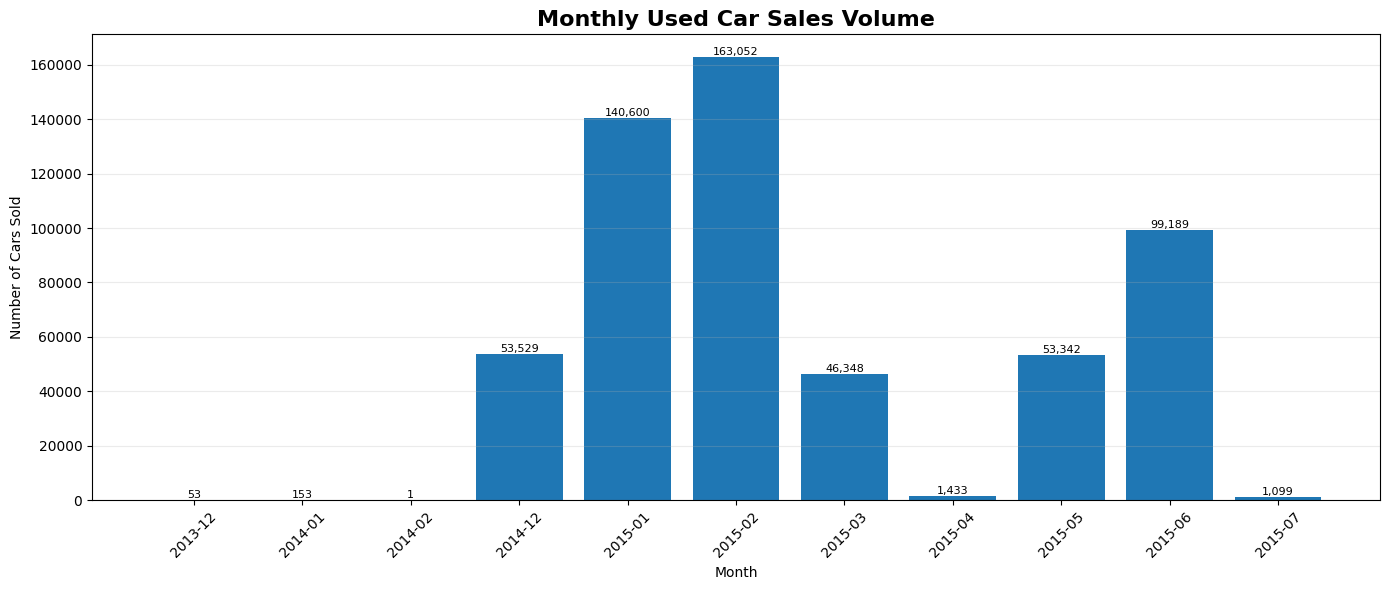

Highest sales month: 2015-02
Highest monthly sales: 163,052 vehicles
Lowest sales month: 2014-02
Lowest monthly sales: 1 vehicles


In [309]:
import pandas as pd
import matplotlib.pyplot as plt

# Prepare monthly sales data
data = df_final.dropna(subset=['sale_date']).copy()
data['sale_date'] = pd.to_datetime(data['sale_date'])

monthly_sales = (
    data.groupby(data['sale_date'].dt.to_period('M'))
    .size()
)

# Plot one simple bar chart
plt.figure(figsize=(14, 6))

bars = plt.bar(
    monthly_sales.index.astype(str),
    monthly_sales.values
)

# Show sales numbers above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:,.0f}',
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.title('Monthly Used Car Sales Volume',
          fontsize=16, fontweight='bold')

plt.xlabel('Month')
plt.ylabel('Number of Cars Sold')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig(
    '/content/charts/01_monthly_sales.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Highest sales month:", monthly_sales.idxmax())
print("Highest monthly sales:", f"{monthly_sales.max():,} vehicles")
print("Lowest sales month:", monthly_sales.idxmin())
print("Lowest monthly sales:", f"{monthly_sales.min():,} vehicles")

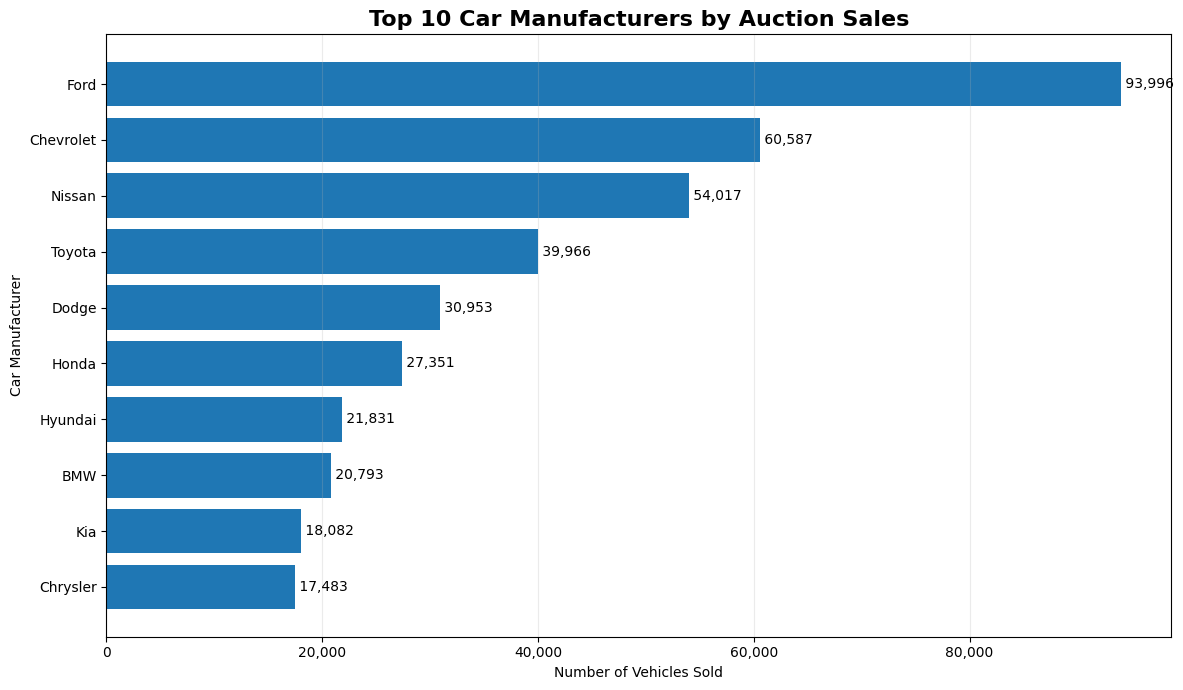

Top-selling manufacturer: Ford
Vehicles sold: 93,996


In [310]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Count vehicles sold by manufacturer
brand_sales = (
    df_final.groupby('make')['sellingprice_inr']
    .count()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    brand_sales.index,
    brand_sales.values
)

# Display exact values
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f' {width:,.0f}',
        va='center',
        fontsize=10
    )

plt.title(
    'Top 10 Car Manufacturers by Auction Sales',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Vehicles Sold')
plt.ylabel('Car Manufacturer')

plt.gca().xaxis.set_major_formatter(
    mticker.StrMethodFormatter('{x:,.0f}')
)

plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.savefig(
    '/content/charts/02_top_10_manufacturers.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

# Business insights
print("Top-selling manufacturer:", brand_sales.idxmax())
print("Vehicles sold:", f"{brand_sales.max():,}")

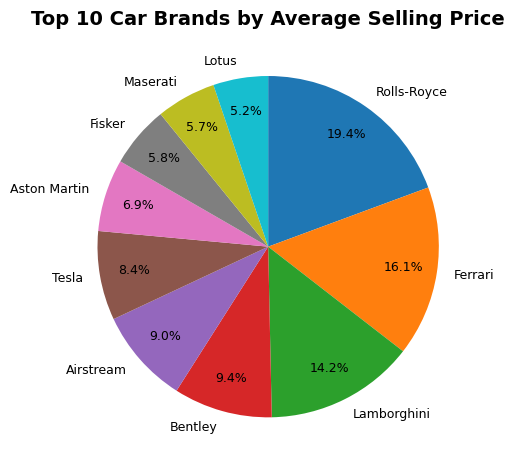

In [311]:
import matplotlib.pyplot as plt

# Calculate average selling price for each brand
brand_prices = (
    df_final.groupby('make')['sellingprice_inr']
    .mean()
    .nlargest(10)
)

# Create pie chart
plt.pie(
    brand_prices.values,
    labels=brand_prices.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,
    pctdistance=0.8,
    textprops={'fontsize': 9}
)

plt.title(
    'Top 10 Car Brands by Average Selling Price',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig(
    '/content/charts/03_top_10_brands_avg_price.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

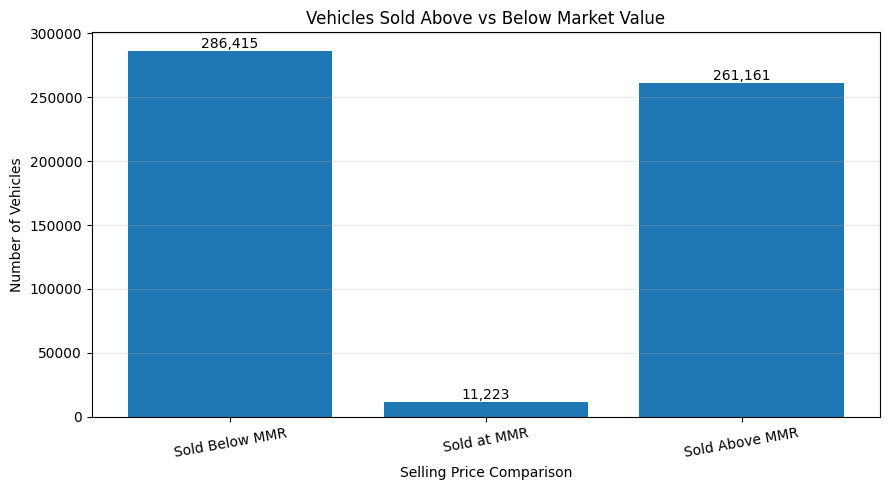

In [312]:
import matplotlib.pyplot as plt
import numpy as np

# Keep records with both prices
comparison = df_final[
    ['mmr_inr', 'sellingprice_inr']
].dropna().copy()

# Classify selling price
comparison['sale_category'] = np.select(
    [
        comparison['sellingprice_inr'] < comparison['mmr_inr'],
        comparison['sellingprice_inr'] > comparison['mmr_inr']
    ],
    [
        'Sold Below MMR',
        'Sold Above MMR'
    ],
    default='Sold at MMR'
)

# Count vehicles in each category
category_counts = comparison['sale_category'].value_counts().reindex(
    ['Sold Below MMR', 'Sold at MMR', 'Sold Above MMR'],
    fill_value=0
)

# Create bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(category_counts.index, category_counts.values)

plt.title('Vehicles Sold Above vs Below Market Value')
plt.xlabel('Selling Price Comparison')
plt.ylabel('Number of Vehicles')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{int(bar.get_height()):,}',
        ha='center',
        va='bottom'
    )

plt.xticks(rotation=10)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.savefig(
    '/content/charts/04_selling_price_vs_mmr.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

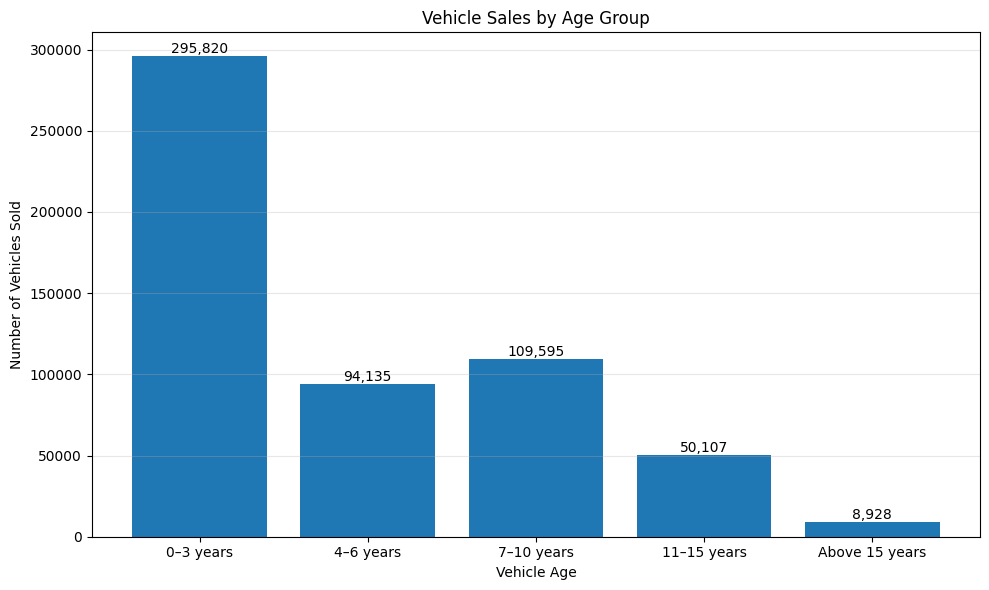

In [313]:
# Calculate vehicle age at the time of sale

age_data = df_final[['year', 'sale_date']].dropna().copy()

age_data['sale_date'] = pd.to_datetime(age_data['sale_date'])
age_data['vehicle_age'] = (
    age_data['sale_date'].dt.year - age_data['year']
)

# Create age groups
age_data['age_group'] = pd.cut(
    age_data['vehicle_age'],
    bins=[-1, 3, 6, 10, 15, 100],
    labels=['0–3 years', '4–6 years', '7–10 years',
            '11–15 years', 'Above 15 years']
)

# Count vehicles sold in each age group
age_counts = age_data['age_group'].value_counts().sort_index()

# Plot
plt.figure(figsize=(10, 6))

bars = plt.bar(age_counts.index.astype(str), age_counts.values)

plt.title('Vehicle Sales by Age Group')
plt.xlabel('Vehicle Age')
plt.ylabel('Number of Vehicles Sold')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{int(bar.get_height()):,}',
        ha='center',
        va='bottom'
    )

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    '/content/charts/05_vehicle_sales_by_age.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

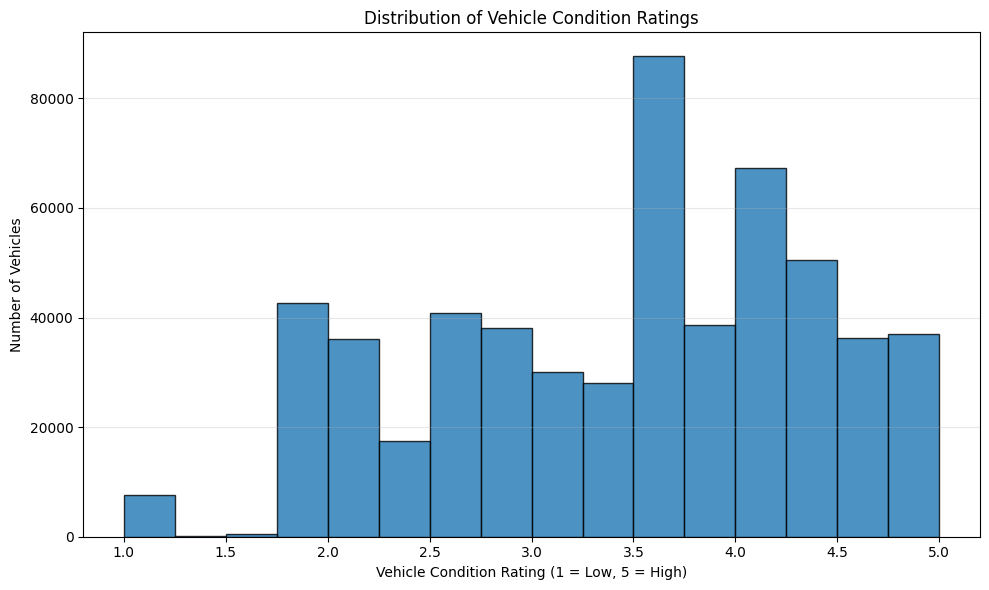

Minimum rating: 1.0
Maximum rating: 5.0
Total vehicles: 558825


In [314]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Convert condition scores
condition_data = df_final['condition'].dropna().copy()

condition_data = np.where(
    condition_data > 5,
    condition_data / 10,
    condition_data
)

# Keep valid ratings between 1 and 5
condition_data = condition_data[
    (condition_data >= 1) & (condition_data <= 5)
]

# Updated histogram
plt.figure(figsize=(10, 6))

plt.hist(
    condition_data,
    bins=np.arange(1, 5.25, 0.25),
    edgecolor='black',
    alpha=0.8
)

plt.title('Distribution of Vehicle Condition Ratings')
plt.xlabel('Vehicle Condition Rating (1 = Low, 5 = High)')
plt.ylabel('Number of Vehicles')

plt.xticks(np.arange(1, 5.1, 0.5))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    '/content/charts/06_vehicle_condition.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

print("Minimum rating:", condition_data.min())
print("Maximum rating:", condition_data.max())
print("Total vehicles:", len(condition_data))

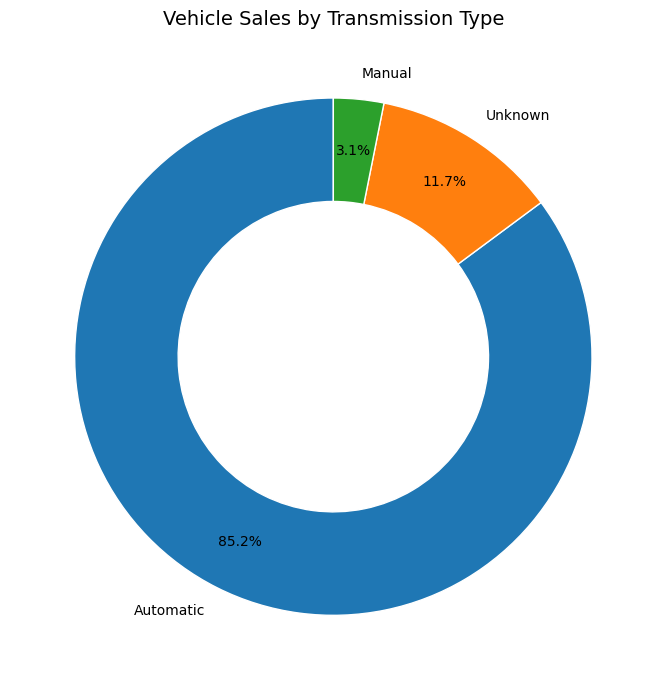

In [315]:

import matplotlib.pyplot as plt

# Count vehicles by transmission type
transmission_sales = df_final['transmission'].dropna().value_counts()

# Create donut chart
plt.figure(figsize=(8, 7))

plt.pie(
    transmission_sales.values,
    labels=transmission_sales.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.8,
    wedgeprops={'width': 0.4, 'edgecolor': 'white'}
)

plt.title('Vehicle Sales by Transmission Type', fontsize=14)

plt.tight_layout()
plt.savefig(
    '/content/charts/07_transmission_type.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [308]:
import os

# Create folder to store all charts
os.makedirs('/content/charts', exist_ok=True)

print("Charts folder created successfully!")

Charts folder created successfully!
